# SHAB extraction benchmark — results analysis

This notebook reads the evaluation outputs (`results/<run>/summary.json`,
`results/<run>/fields.csv`) and the raw responses (`runs/<run>/raw/*.json`).
It is read-only with respect to `data/`, `runs/` and `results/`; it writes
figures to `notebooks/figures/` only.

The holdout split (50 AG notices, annotated after the prompt freeze) is the
primary result; the dev split (120 notices) is secondary. Scores are the
normalized comparison mode throughout, as in the headline of `summary.json`.

Interpretation of the results is deliberately left out of this notebook
(section 10).

In [1]:
import io
import json
import subprocess
import sys
import unicodedata
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").is_file())
# The project rule is to use the .venv interpreter only.
assert Path(sys.executable).resolve().is_relative_to((ROOT / ".venv").resolve()), sys.executable

RESULTS = ROOT / "results"
RUNS = ROOT / "runs"
FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

MODELS = [
    "gpt-6-luna",
    "gpt-6.1-sol",
    "claude-haiku-5.5",
    "claude-sonnet-5.5",
    "gemini-3.5-flash-lite",
    "mistral-large-4-0",
    "gemma-3-12b-it-deepinfra",
]
BASELINES = ["trivial", "rules"]
COMPETITORS = [f"baseline-{b}" for b in BASELINES] + MODELS
SPLITS = ["holdout", "dev"]  # holdout first: it is the primary result
NEXTBIT_RUN = "dev-gemma-3-12b-it"  # section 8 only


def run_id(competitor, split):
    if competitor.startswith("baseline-"):
        return f"{competitor}-{split}"
    return f"{split}-{competitor}"


MAIN_RUNS = {split: {c: run_id(c, split) for c in COMPETITORS} for split in SPLITS}

## 0. Loading

Three loaders, one per source. `load_summary` and `load_fields` accept an
optional git ref, used in section 9 to read the results as they were at the
tag `pre-gold-correction` (via `git show`, without touching the working tree).
`fields.csv` is read with every column as text: `gold` and `prediction` are
JSON-encoded, and empty `item` / `attribute` cells mark field-level rows.

In [2]:
def _git_show(ref, path):
    out = subprocess.run(
        ["git", "show", f"{ref}:{path}"], cwd=ROOT, capture_output=True, check=True
    )
    return out.stdout.decode("utf-8")


def load_summary(run, ref=None):
    path = f"results/{run}/summary.json"
    if ref is None:
        return json.loads((ROOT / path).read_text(encoding="utf-8"))
    return json.loads(_git_show(ref, path))


def load_fields(run, ref=None):
    path = f"results/{run}/fields.csv"
    source = ROOT / path if ref is None else io.StringIO(_git_show(ref, path))
    df = pd.read_csv(source, dtype=str, keep_default_na=False, encoding="utf-8")
    df["gold_json"] = df["gold"].map(json.loads)
    df["pred_json"] = df["prediction"].map(json.loads)
    return df


def load_raw(run):
    rows = []
    for path in sorted((RUNS / run / "raw").glob("*.json")):
        r = json.loads(path.read_text(encoding="utf-8"))
        usage = r.get("usage") or {}
        rows.append(
            {
                "doc_id": r["doc_id"],
                "status": r.get("status"),
                "finish_reason": r.get("finish_reason"),
                "attempts": r.get("attempts"),
                "provider_served": r.get("provider_served"),
                "cost_usd": r.get("cost_usd"),
                "latency_ms": r.get("latency_ms"),
                "reasoning_tokens": r.get("reasoning_tokens"),
                "prompt_tokens": usage.get("prompt_tokens"),
                "completion_tokens": usage.get("completion_tokens"),
                "response_chars": r.get("response_chars"),
                "timestamp": pd.Timestamp(r["timestamp"]),
                "error": r.get("error"),
                "usage": usage,
            }
        )
    return pd.DataFrame(rows)


ALL_RUNS = sorted({r for split in SPLITS for r in MAIN_RUNS[split].values()} | {NEXTBIT_RUN})
FIELDS = {run: load_fields(run) for run in ALL_RUNS}
SUMMARIES = {run: load_summary(run) for run in ALL_RUNS}

pd.DataFrame(
    {
        "rows": {run: len(df) for run, df in FIELDS.items()},
        "documents": {run: df["doc_id"].nunique() for run, df in FIELDS.items()},
        "n_docs (summary)": {run: s["run"]["n_docs"] for run, s in SUMMARIES.items()},
    }
)

,rows,documents,n_docs (summary)
baseline-rules-dev,3764,120,120
baseline-rules-holdout,1554,50,50
baseline-trivial-dev,3764,120,120
baseline-trivial-holdout,1554,50,50
dev-claude-haiku-5.5,4930,120,120
dev-claude-sonnet-5.5,4930,120,120
dev-gemini-3.5-flash-lite,4930,120,120
dev-gemma-3-12b-it,4360,120,120
dev-gemma-3-12b-it-deepinfra,4778,120,120
dev-gpt-6-luna,4930,120,120


In [3]:
# Unique values of outcome_normalized, counted over every loaded run.
all_rows = pd.concat([df.assign(run=run) for run, df in FIELDS.items()], ignore_index=True)
all_rows["outcome_normalized"].value_counts().rename("rows").to_frame()

,rows
outcome_normalized,
correct,31184
correct_null,23745
omission,2118
wrong,2075
no_output,1947
matched,1445
missed,933
excluded_uncertain,404
hallucination,368


The six scalar outcomes (`correct`, `correct_null`, `omission`, `wrong`,
`hallucination`, `no_output`) apply to the 29 field-level fields and to the
attributes of matched persons. `matched` / `missed` / `spurious` are
list-item outcomes for persons and `extras` keys; `spurious_unregistered`
is an `extras` key outside the registry. `excluded_uncertain` marks a field
the annotator listed in the gold record's `uncertain`; it is not scored.

## 1. Reproducing summary.json from fields.csv

Every metric in `summary.json` is a **micro-average**: per-document
numerators and denominators are summed over all documents first, and the
ratio is taken once, `Σ numerator / Σ denominator`. It is not a mean of
per-document or per-field ratios. This also makes the document the
resampling unit for the bootstrap: a resample re-weights whole documents.

The functions below rebuild the per-document `(numerator, denominator)`
pairs from `fields.csv` alone, independently of `src/evaluate.py`:

- *accuracy*: `correct + correct_null` over all scored rows;
- *value accuracy*: `correct` over the rows whose gold has a value (an empty
  list counts as null for the set fields `act_subtypes` and
  `alternative_names`); these rows can only be `correct`, `omission`,
  `wrong` or `no_output`;
- *null accuracy*: `correct_null` over the rows whose gold is null;
- *F1* as a ratio of sums, `2TP / (2TP + FP + FN)`: persons (TP = `matched`,
  FN = `missed` + `no_output`, FP = `spurious`), `extras` keys (TP = shared
  registered keys, FP = `spurious` + `spurious_unregistered`, FN = `missed` +
  `no_output`) and `act_subtypes` labels (from the gold and predicted lists).

The field groups are copied from `src/evaluate.py` and checked against the
lists stored in each `summary.json`.

In [4]:
HEADER_FIELDS = (
    "act_type", "company_name_full", "company_name_base", "status_suffix",
    "alternative_names", "uid", "legal_form", "seat_municipality", "seat_canton",
    "address_care_of", "address_street", "address_postcode", "address_municipality",
    "tagesregister_nr", "tagesregister_date", "prior_publication_shab_nr",
    "prior_publication_date", "prior_publication_id", "authority",
)
COMPREHENSION_FIELDS = (
    "act_subtypes", "company_name_new", "company_name_previous", "act_date",
    "canton_previous", "canton_new", "capital_new_chf", "capital_previous_chf",
    "domicile_new", "domicile_previous",
)
GROUPS = {"comprehension": COMPREHENSION_FIELDS, "header": HEADER_FIELDS}
FIELD_LEVEL = set(HEADER_FIELDS) | set(COMPREHENSION_FIELDS)
SET_FIELDS = {"act_subtypes", "alternative_names"}
PERSON_FIELDS = ("persons_added", "persons_removed", "persons_changed")
OK_OUTCOMES = {"correct", "correct_null"}
EXCLUDED = "excluded_uncertain"

for s in SUMMARIES.values():
    for group, fields in GROUPS.items():
        assert tuple(s["groups"][group]["fields"]) == fields, group


def gold_is_null(field, value):
    if field in SET_FIELDS:
        return value is None or value == []
    return value is None


def _normalize_label(value):
    # Same normalization as the harness: NFC, collapsed whitespace, casefold.
    if not isinstance(value, str):
        return json.dumps(value, sort_keys=True)
    text = re.sub(r"\s+", " ", unicodedata.normalize("NFC", value)).strip()
    return unicodedata.normalize("NFC", text.casefold())


def _label_set(value):
    if value is None:
        return set()
    items = value if isinstance(value, list) else [value]
    return {_normalize_label(v) for v in items}


def _field_rows(df, fields):
    rows = df[(df["item"] == "") & df["field"].isin(fields)]
    return rows[rows["outcome_normalized"] != EXCLUDED]


def _per_doc(df, rows, num, den):
    docs = sorted(df["doc_id"].unique())
    out = pd.DataFrame({"num": num, "den": den, "doc_id": rows["doc_id"]})
    return out.groupby("doc_id")[["num", "den"]].sum().reindex(docs, fill_value=0)


def doc_ratios(df, metric):
    # Per-document (num, den) for one metric, indexed by doc_id.
    name, _, arg = metric.partition(":")
    # accuracy
    if name in ("core_accuracy_normalized", "group_accuracy_normalized"):
        rows = _field_rows(df, GROUPS[arg] if arg else FIELD_LEVEL)
        ok = rows["outcome_normalized"].isin(OK_OUTCOMES).astype(int)
        return _per_doc(df, rows, ok, 1)
    # value accuracy / null accuracy
    if name in ("group_value_accuracy_normalized", "group_null_accuracy_normalized",
                "value_accuracy_normalized", "null_accuracy_normalized"):
        fields = GROUPS[arg] if name.startswith("group_") else (arg,)
        rows = _field_rows(df, fields)
        is_null = [gold_is_null(f, g) for f, g in zip(rows["field"], rows["gold_json"])]
        rows = rows[np.array(is_null) == name.startswith(("group_null", "null"))]
        hit = "correct_null" if "null" in name else "correct"
        assert set(rows["outcome_normalized"]) <= (
            {"correct_null", "hallucination", "no_output"} if hit == "correct_null"
            else {"correct", "omission", "wrong", "no_output"}
        )
        return _per_doc(df, rows, (rows["outcome_normalized"] == hit).astype(int), 1)
    if name == "persons_found_f1":
        rows = df[(df["field"] == arg) & (df["attribute"] == "") & (df["outcome_normalized"] != EXCLUDED)]
        o = rows["outcome_normalized"]
        tp, fp, fn = (o == "matched"), (o == "spurious"), o.isin({"missed", "no_output"})
        return _per_doc(df, rows, 2 * tp, 2 * tp + fp + fn)
    if name == "extras_key_f1":
        rows = df[(df["field"] == "extras") & (df["outcome_normalized"] != EXCLUDED)]
        o = rows["outcome_normalized"]
        tp = o.isin({"correct", "wrong"})
        fp = o.isin({"spurious", "spurious_unregistered"})
        fn = o.isin({"missed", "no_output"})
        return _per_doc(df, rows, 2 * tp, 2 * tp + fp + fn)
    if name == "act_subtypes_micro_f1":
        rows = _field_rows(df, ("act_subtypes",))
        tp, fp, fn = [], [], []
        for g, p in zip(rows["gold_json"], rows["pred_json"]):
            gs, ps = _label_set(g), _label_set(p)
            tp.append(len(gs & ps)); fp.append(len(ps - gs)); fn.append(len(gs - ps))
        tp, fp, fn = map(np.array, (tp, fp, fn))
        return _per_doc(df, rows, 2 * tp, 2 * tp + fp + fn)
    raise KeyError(metric)


def micro(df, metric):
    r = doc_ratios(df, metric)
    return int(r["num"].sum()), int(r["den"].sum())

In [5]:
# The requested check: comprehension value accuracy of dev-gpt-6.1-sol.
run = "dev-gpt-6.1-sol"
metric = "group_value_accuracy_normalized:comprehension"
num, den = micro(FIELDS[run], metric)
h = SUMMARIES[run]["headline"][metric]
print(f"fields.csv  : {num}/{den} = {num / den:.3f}")
print(f"summary.json: {h['numerator']}/{h['denominator']} = {h['value']:.3f}")
assert (num, den) == (203, 204) == (h["numerator"], h["denominator"])

# The per-field breakdown of the 204 denominator.
rows = _field_rows(FIELDS[run], COMPREHENSION_FIELDS)
rows = rows[[not gold_is_null(f, g) for f, g in zip(rows["field"], rows["gold_json"])]]
pd.crosstab(rows["field"], rows["outcome_normalized"], margins=True)

fields.csv  : 203/204 = 0.995
summary.json: 203/204 = 0.995


outcome_normalized,correct,wrong,All
field,,,
act_date,36,0,36
act_subtypes,74,1,75
canton_new,6,0,6
canton_previous,6,0,6
capital_new_chf,11,0,11
capital_previous_chf,1,0,1
company_name_new,9,0,9
company_name_previous,9,0,9
domicile_new,26,0,26


In [6]:
# A second metric: act_subtypes micro-F1 for the same run (rebuilt from the
# gold and predicted label lists), then every key metric of every loaded
# run against summary.json (numerator and denominator must match exactly).
metric = "act_subtypes_micro_f1"
num, den = micro(FIELDS[run], metric)
h = SUMMARIES[run]["headline"][metric]
print(f"{metric}: fields.csv {num}/{den} = {num / den:.3f}, "
      f"summary.json {h['numerator']}/{h['denominator']} = {h['value']:.3f}")
assert (num, den) == (h["numerator"], h["denominator"])

KEY_METRICS = {
    "group_value_accuracy_normalized:comprehension": "comp. value acc",
    "group_null_accuracy_normalized:comprehension": "comp. null acc",
    "persons_found_f1:persons_added": "F1 persons_added",
    "persons_found_f1:persons_removed": "F1 persons_removed",
    "persons_found_f1:persons_changed": "F1 persons_changed",
    "act_subtypes_micro_f1": "act_subtypes micro-F1",
    "extras_key_f1": "extras key F1",
    "group_accuracy_normalized:header": "header acc",
    "core_accuracy_normalized": "global acc",
}
CHECKED = list(KEY_METRICS) + [
    "group_accuracy_normalized:comprehension",
    "group_value_accuracy_normalized:header",
    "group_null_accuracy_normalized:header",
] + [f"{kind}:{f}" for f in sorted(FIELD_LEVEL)
     for kind in ("value_accuracy_normalized", "null_accuracy_normalized")]

check = []
for run in ALL_RUNS:
    for metric in CHECKED:
        h = SUMMARIES[run]["headline"][metric]
        num, den = micro(FIELDS[run], metric)
        check.append({"run": run, "metric": metric, "fields_csv": (num, den),
                      "summary_json": (h["numerator"], h["denominator"])})
check = pd.DataFrame(check)
mismatches = check[check["fields_csv"] != check["summary_json"]]
print(f"{len(check)} (run, metric) pairs compared, {len(mismatches)} mismatches")
assert mismatches.empty, mismatches

act_subtypes_micro_f1: fields.csv 232/233 = 0.996, summary.json 232/233 = 0.996


1330 (run, metric) pairs compared, 0 mismatches


## 2. Main results table

Point estimates and 95% bootstrap intervals are read from `summary.json`
(percentile bootstrap, 10,000 resamples of documents, seed 20261011); they
are not recomputed here. Metrics follow the report order fixed in
`CLAUDE.md`: comprehension value and null accuracy, person-list F1,
`act_subtypes` micro-F1, `extras` key F1, header accuracy, global accuracy
last. Baselines are included as floors.

In [7]:
def headline_long(runs_by_competitor, summaries=None, ref=None):
    rows = []
    for competitor, run in runs_by_competitor.items():
        s = summaries[run] if summaries else load_summary(run, ref)
        for metric, label in KEY_METRICS.items():
            h = s["headline"][metric]
            rows.append({"competitor": competitor, "run": run, "metric": metric, "label": label,
                         "value": h["value"], "ci_low": h["ci_low"], "ci_high": h["ci_high"],
                         "numerator": h["numerator"], "denominator": h["denominator"]})
    return pd.DataFrame(rows)


def fmt_cell(r):
    if r["value"] is None or pd.isna(r["value"]):
        return "n/a"
    if r["ci_low"] is None or pd.isna(r["ci_low"]):
        return f"{r['value']:.3f}"
    return f"{r['value']:.3f} [{r['ci_low']:.3f}, {r['ci_high']:.3f}]"


def wide_table(long):
    t = long.assign(cell=long.apply(fmt_cell, axis=1))
    t = t.pivot(index="competitor", columns="label", values="cell")
    return t.loc[[c for c in COMPETITORS if c in t.index], list(KEY_METRICS.values())]


HEADLINE = {split: headline_long(MAIN_RUNS[split], SUMMARIES) for split in SPLITS}
print("HOLDOUT (AG, n = 50) — primary result")
wide_table(HEADLINE["holdout"])

HOLDOUT (AG, n = 50) — primary result


label,comp. value acc,comp. null acc,F1 persons_added,F1 persons_removed,F1 persons_changed,act_subtypes micro-F1,extras key F1,header acc,global acc
competitor,,,,,,,,,
baseline-trivial,"0.000 [0.000, 0.000]","1.000 [1.000, 1.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.227 [0.213, 0.241]","0.418 [0.396, 0.438]"
baseline-rules,"0.000 [0.000, 0.000]","1.000 [1.000, 1.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.995 [0.990, 0.999]","0.924 [0.903, 0.942]"
gpt-6-luna,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.901 [0.769, 0.968]","0.998 [0.995, 1.000]","0.999 [0.997, 1.000]"
gpt-6.1-sol,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]"
claude-haiku-5.5,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.974 [0.925, 1.000]","0.999 [0.997, 1.000]","0.999 [0.998, 1.000]"
claude-sonnet-5.5,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.987 [0.947, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]"
gemini-3.5-flash-lite,"0.867 [0.776, 0.961]","0.995 [0.983, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.951 [0.917, 0.984]","1.000 [1.000, 1.000]","0.998 [0.995, 1.000]","0.987 [0.977, 0.996]"
mistral-large-4-0,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]"
gemma-3-12b-it-deepinfra,"0.676 [0.595, 0.744]","0.951 [0.926, 0.972]","0.686 [0.500, 0.839]","0.930 [0.800, 1.000]","0.902 [0.778, 0.977]","0.391 [0.225, 0.554]","0.710 [0.525, 0.857]","0.879 [0.860, 0.895]","0.883 [0.865, 0.899]"


In [8]:
print("DEV (BE/LU/ZH, n = 120) — secondary")
wide_table(HEADLINE["dev"])

DEV (BE/LU/ZH, n = 120) — secondary


label,comp. value acc,comp. null acc,F1 persons_added,F1 persons_removed,F1 persons_changed,act_subtypes micro-F1,extras key F1,header acc,global acc
competitor,,,,,,,,,
baseline-trivial,"0.000 [0.000, 0.000]","1.000 [1.000, 1.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.323 [0.298, 0.349]","0.497 [0.476, 0.517]"
baseline-rules,"0.000 [0.000, 0.000]","1.000 [1.000, 1.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","1.000 [0.999, 1.000]","0.941 [0.933, 0.949]"
gpt-6-luna,"0.975 [0.943, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.996 [0.985, 1.000]","0.965 [0.932, 0.987]","0.998 [0.996, 1.000]","0.997 [0.995, 0.999]"
gpt-6.1-sol,"0.995 [0.984, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.996 [0.986, 1.000]","0.996 [0.987, 1.000]","1.000 [1.000, 1.000]","1.000 [0.999, 1.000]"
claude-haiku-5.5,"0.990 [0.974, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.991 [0.978, 1.000]","0.981 [0.962, 0.996]","1.000 [1.000, 1.000]","0.999 [0.999, 1.000]"
claude-sonnet-5.5,"0.980 [0.946, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.991 [0.978, 1.000]","0.985 [0.966, 0.997]","1.000 [1.000, 1.000]","0.999 [0.997, 1.000]"
gemini-3.5-flash-lite,"0.931 [0.887, 0.970]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.985 [0.945, 1.000]","0.983 [0.967, 0.996]","0.989 [0.971, 1.000]","0.996 [0.992, 0.999]","0.993 [0.989, 0.996]"
mistral-large-4-0,"0.980 [0.952, 1.000]","0.992 [0.975, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.954 [0.880, 1.000]","0.987 [0.965, 1.000]","0.957 [0.880, 0.996]","0.992 [0.975, 1.000]","0.991 [0.974, 1.000]"
gemma-3-12b-it-deepinfra,"0.598 [0.527, 0.665]","0.977 [0.967, 0.986]","0.876 [0.813, 0.929]","0.984 [0.945, 1.000]","0.697 [0.538, 0.822]","0.440 [0.323, 0.552]","0.650 [0.535, 0.758]","0.902 [0.890, 0.914]","0.905 [0.895, 0.915]"


In [9]:
# Numerators and denominators behind the two tables.
counts = pd.concat(HEADLINE, names=["split"]).reset_index(level=0)
counts.assign(n=counts["numerator"].astype(str) + "/" + counts["denominator"].astype(str)).pivot(
    index=["split", "competitor"], columns="label", values="n"
).loc[:, list(KEY_METRICS.values())]

label                            comp. value acc comp. null acc F1 persons_added F1 persons_removed F1 persons_changed act_subtypes micro-F1 extras key F1 header acc global acc
split   competitor                                                                                                                                                              
dev     baseline-rules                     0/204        986/986             0/76               0/31               0/32                 0/117         0/132  2276/2277  3262/3467
        baseline-trivial                   0/204        986/986             0/76               0/31               0/32                 0/117         0/132   736/2277  1722/3467
        claude-haiku-5.5                 202/204        986/986          152/152              62/62              64/64               230/232       256/261  2277/2277  3465/3467
        claude-sonnet-5.5                200/204        986/986          152/152              62/62              64/64               230/232       258/262  2277/2277  3463/3467
        gemini-3.5-flash-lite            190/204        986/986          152/152              62/62              64/65               234/238       258/261  2267/2277  3443/3467
        gemma-3-12b-it-deepinfra         122/204        963/986          134/153              62/63              46/66                66/150       134/206  2053/2277  3138/3467
        gpt-6-luna                       199/204        986/986          152/152              62/62              64/64               232/233       248/257  2273/2277  3458/3467
        gpt-6.1-sol                      203/204        986/986          152/152              62/62              64/64               232/233       264/265  2277/2277  3466/3467
        mistral-large-4-0                200/204        978/986          152/152              62/62              62/65               230/233       246/257  2258/2277  3436/3467
holdout baseline-rules                     0/105        386/386             0/13               0/21               0/27                  0/72          0/39    942/947  1328/1438
        baseline-trivial                   0/105        386/386             0/13               0/21               0/27                  0/72          0/39    215/947   601/1438
        claude-haiku-5.5                 105/105        386/386            26/26              42/42              54/54               144/144         74/76    946/947  1437/1438
        claude-sonnet-5.5                105/105        386/386            26/26              42/42              54/54               144/144         76/77    947/947  1438/1438
        gemini-3.5-flash-lite             91/105        384/386            26/26              42/42              54/54               136/143         78/78    945/947  1420/1438
        gemma-3-12b-it-deepinfra          71/105        367/386            24/35              40/43              46/51                 36/92         44/62    832/947  1270/1438
        gpt-6-luna                       105/105        386/386            26/26              42/42              54/54               144/144         64/71    945/947  1436/1438
        gpt-6.1-sol                      105/105        386/386            26/26              42/42              54/54               144/144         78/78    947/947  1438/1438
        mistral-large-4-0                105/105        386/386            26/26              42/42              54/54               144/144         78/78    947/947  1438/1438

## 3. Cells with zero errors: Clopper–Pearson intervals

When a run makes no error on a metric in any document, every bootstrap
resample is drawn from documents that are all perfect, so every resampled
ratio is exactly 1 and the percentile interval collapses to `[1, 1]`. That
interval reflects the absence of variation in the sample, not certainty
about the population: with `n` scored items, an error rate of up to roughly
`3/n` is still compatible with observing zero errors (the "rule of three").

For these cells an exact binomial (Clopper–Pearson) interval is reported
instead, treating each scored item as a Bernoulli trial
(`proportion_confint(count, nobs, method="beta")`). Two caveats:
items within one notice are not independent, so this interval is, if
anything, too narrow; and it applies only to accuracy-type metrics. F1 is
not a proportion of independent trials, so F1 cells at 1.0 are listed
without an exact interval.

In [10]:
ACCURACY_METRICS = {m for m in KEY_METRICS if "accuracy" in m}

zero = pd.concat(HEADLINE, names=["split"]).reset_index(level=0)
zero = zero[(zero["denominator"] > 0) & (zero["numerator"] == zero["denominator"])].copy()
zero["bootstrap CI"] = zero.apply(lambda r: f"[{r['ci_low']:.3f}, {r['ci_high']:.3f}]", axis=1)


def cp_cell(r):
    if r["metric"] not in ACCURACY_METRICS:
        return "n/a (F1)"
    lo, hi = proportion_confint(r["numerator"], r["denominator"], alpha=0.05, method="beta")
    return f"[{lo:.3f}, {hi:.3f}]"


zero["Clopper-Pearson 95%"] = zero.apply(cp_cell, axis=1)
zero["rule of three (1 - 3/n)"] = np.where(
    zero["metric"].isin(ACCURACY_METRICS), (1 - 3 / zero["denominator"]).round(3), np.nan
)
zero["n"] = zero["denominator"]
zero[["split", "competitor", "label", "n", "bootstrap CI", "Clopper-Pearson 95%",
      "rule of three (1 - 3/n)"]].reset_index(drop=True)

,split,competitor,label,n,bootstrap CI,Clopper-Pearson 95%,rule of three (1 - 3/n)
0,holdout,baseline-trivial,comp. null acc,386,"[1.000, 1.000]","[0.990, 1.000]",0.992
1,holdout,baseline-rules,comp. null acc,386,"[1.000, 1.000]","[0.990, 1.000]",0.992
2,holdout,gpt-6-luna,comp. value acc,105,"[1.000, 1.000]","[0.965, 1.000]",0.971
3,holdout,gpt-6-luna,comp. null acc,386,"[1.000, 1.000]","[0.990, 1.000]",0.992
4,holdout,gpt-6-luna,F1 persons_added,26,"[1.000, 1.000]",n/a (F1),NaN
5,holdout,gpt-6-luna,F1 persons_removed,42,"[1.000, 1.000]",n/a (F1),NaN
6,holdout,gpt-6-luna,F1 persons_changed,54,"[1.000, 1.000]",n/a (F1),NaN
7,holdout,gpt-6-luna,act_subtypes micro-F1,144,"[1.000, 1.000]",n/a (F1),NaN
8,holdout,gpt-6.1-sol,comp. value acc,105,"[1.000, 1.000]","[0.965, 1.000]",0.971
9,holdout,gpt-6.1-sol,comp. null acc,386,"[1.000, 1.000]","[0.990, 1.000]",0.992


## 4. Paired bootstrap of differences between models

Two models scored on the same notices are not independent samples: a hard
notice is hard for both. `paired_bootstrap` therefore draws one set of
document indices per resample and applies it to both runs, recomputes each
run's micro-average on that resample, and takes the difference. The 95%
interval is the 2.5th–97.5th percentile of the 10,000 differences.
Resamples in which either denominator is zero are dropped (`n_valid`).

Only one question is asked of each interval: does it include 0? Several
pairs and metrics are tested, so an interval that excludes 0 should be read
with the number of comparisons in mind.

In [11]:
def paired_bootstrap(run_a, run_b, metric, n=10_000, seed=42):
    a = doc_ratios(FIELDS[run_a], metric)
    b = doc_ratios(FIELDS[run_b], metric)
    assert list(a.index) == list(b.index), "the two runs must cover the same documents"
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), size=(n, len(a)))
    num_a, den_a = a["num"].to_numpy()[idx].sum(1), a["den"].to_numpy()[idx].sum(1)
    num_b, den_b = b["num"].to_numpy()[idx].sum(1), b["den"].to_numpy()[idx].sum(1)
    valid = (den_a > 0) & (den_b > 0)
    diffs = num_a[valid] / den_a[valid] - num_b[valid] / den_b[valid]
    point_a = a["num"].sum() / a["den"].sum()
    point_b = b["num"].sum() / b["den"].sum()
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return {"a": run_a, "b": run_b, "metric": KEY_METRICS.get(metric, metric),
            "value_a": point_a, "value_b": point_b, "diff (a - b)": point_a - point_b,
            "ci_low": lo, "ci_high": hi, "n_valid": int(valid.sum()),
            "CI includes 0": bool(lo <= 0 <= hi)}


PAIRS = [
    ("dev-gpt-6.1-sol", "dev-gpt-6-luna"),
    ("holdout-claude-haiku-5.5", "holdout-gemini-3.5-flash-lite"),
    ("dev-claude-haiku-5.5", "dev-gemini-3.5-flash-lite"),
    ("dev-gpt-6-luna", "dev-claude-sonnet-5.5"),
]
PAIR_METRICS = [
    "group_value_accuracy_normalized:comprehension",
    "group_null_accuracy_normalized:comprehension",
    "core_accuracy_normalized",
]
paired = pd.DataFrame([paired_bootstrap(a, b, m) for a, b in PAIRS for m in PAIR_METRICS])
paired.round(4)

,a,b,metric,value_a,value_b,diff (a - b),ci_low,ci_high,n_valid,CI includes 0
0,dev-gpt-6.1-sol,dev-gpt-6-luna,comp. value acc,0.9951,0.9755,0.0196,-0.0053,0.0538,10000,True
1,dev-gpt-6.1-sol,dev-gpt-6-luna,comp. null acc,1.0000,1.0000,0.0000,0.0000,0.0000,10000,True
2,dev-gpt-6.1-sol,dev-gpt-6-luna,global acc,0.9997,0.9974,0.0023,0.0003,0.0049,10000,False
3,holdout-claude-haiku-5.5,holdout-gemini-3.5-flash-lite,comp. value acc,1.0000,0.8667,0.1333,0.0400,0.2250,10000,False
4,holdout-claude-haiku-5.5,holdout-gemini-3.5-flash-lite,comp. null acc,1.0000,0.9948,0.0052,0.0000,0.0166,10000,True
5,holdout-claude-haiku-5.5,holdout-gemini-3.5-flash-lite,global acc,0.9993,0.9875,0.0118,0.0028,0.0229,10000,False
6,dev-claude-haiku-5.5,dev-gemini-3.5-flash-lite,comp. value acc,0.9902,0.9314,0.0588,0.0155,0.1073,10000,False
7,dev-claude-haiku-5.5,dev-gemini-3.5-flash-lite,comp. null acc,1.0000,1.0000,0.0000,0.0000,0.0000,10000,True
8,dev-claude-haiku-5.5,dev-gemini-3.5-flash-lite,global acc,0.9994,0.9931,0.0063,0.0029,0.0101,10000,False
9,dev-gpt-6-luna,dev-claude-sonnet-5.5,comp. value acc,0.9755,0.9804,-0.0049,-0.0469,0.0377,10000,True


## 5. Notices extracted without any error (post-hoc)

**Post-hoc analysis.** This metric was not among those fixed on 2026-10-11
before scoring; it is reported as a descriptive complement only.

A notice counts as fully correct when every scored field-level field (the 29
of the header and comprehension groups, excluding fields marked uncertain)
is `correct` or `correct_null`. A stricter variant also requires the three
person lists to be exact: no missed or spurious person and every attribute
of every matched person `correct` or `correct_null`. `extras` is left out of
both, as it is scored separately. Intervals are Clopper–Pearson over
notices, which are the independent unit here.

In [12]:
def perfect_docs(df):
    field_rows = _field_rows(df, FIELD_LEVEL)
    fields_ok = field_rows.groupby("doc_id")["outcome_normalized"].apply(lambda o: o.isin(OK_OUTCOMES).all())
    person_rows = df[df["field"].isin(PERSON_FIELDS) & (df["outcome_normalized"] != EXCLUDED)]
    person_ok = person_rows.groupby("doc_id")["outcome_normalized"].apply(
        lambda o: o.isin(OK_OUTCOMES | {"matched"}).all()
    )
    person_ok = person_ok.reindex(fields_ok.index, fill_value=True)  # no persons in gold or prediction
    return fields_ok, fields_ok & person_ok


def ci_text(k, n):
    lo, hi = proportion_confint(k, n, alpha=0.05, method="beta")
    return f"{k}/{n} = {k / n:.3f} [{lo:.3f}, {hi:.3f}]"


rows = []
for split in SPLITS:
    for competitor, run in MAIN_RUNS[split].items():
        fields_ok, all_ok = perfect_docs(FIELDS[run])
        rows.append({"split": split, "competitor": competitor,
                     "fields only": ci_text(int(fields_ok.sum()), len(fields_ok)),
                     "fields + persons": ci_text(int(all_ok.sum()), len(all_ok))})
pd.DataFrame(rows).set_index(["split", "competitor"])

fields only                fields + persons
split   competitor                                                                              
holdout baseline-trivial             0/50 = 0.000 [0.000, 0.071]     0/50 = 0.000 [0.000, 0.071]
        baseline-rules               3/50 = 0.060 [0.013, 0.165]     1/50 = 0.020 [0.001, 0.106]
        gpt-6-luna                  48/50 = 0.960 [0.863, 0.995]    46/50 = 0.920 [0.808, 0.978]
        gpt-6.1-sol                 50/50 = 1.000 [0.929, 1.000]    50/50 = 1.000 [0.929, 1.000]
        claude-haiku-5.5            49/50 = 0.980 [0.894, 0.999]    47/50 = 0.940 [0.835, 0.987]
        claude-sonnet-5.5           50/50 = 1.000 [0.929, 1.000]    50/50 = 1.000 [0.929, 1.000]
        gemini-3.5-flash-lite       42/50 = 0.840 [0.709, 0.928]    37/50 = 0.740 [0.597, 0.854]
        mistral-large-4-0           50/50 = 1.000 [0.929, 1.000]    50/50 = 1.000 [0.929, 1.000]
        gemma-3-12b-it-deepinfra     1/50 = 0.020 [0.001, 0.106]     0/50 = 0.000 [0.000, 0.071]
dev     baseline-trivial            0/120 = 0.000 [0.000, 0.030]    0/120 = 0.000 [0.000, 0.030]
        baseline-rules             15/120 = 0.125 [0.072, 0.198]    4/120 = 0.033 [0.009, 0.083]
        gpt-6-luna                114/120 = 0.950 [0.894, 0.981]  114/120 = 0.950 [0.894, 0.981]
        gpt-6.1-sol               119/120 = 0.992 [0.954, 1.000]  118/120 = 0.983 [0.941, 0.998]
        claude-haiku-5.5          118/120 = 0.983 [0.941, 0.998]  115/120 = 0.958 [0.905, 0.986]
        claude-sonnet-5.5         118/120 = 0.983 [0.941, 0.998]  116/120 = 0.967 [0.917, 0.991]
        gemini-3.5-flash-lite     104/120 = 0.867 [0.793, 0.922]   94/120 = 0.783 [0.699, 0.853]
        mistral-large-4-0         117/120 = 0.975 [0.929, 0.995]  115/120 = 0.958 [0.905, 0.986]
        gemma-3-12b-it-deepinfra    6/120 = 0.050 [0.019, 0.106]    3/120 = 0.025 [0.005, 0.071]

## 6. Failure analysis

Failures are counted on the field-level fields by outcome type
(`omission`: gold has a value, prediction null; `wrong`: both non-null but
different; `hallucination`: gold null, prediction non-null; `no_output`: the
response could not be parsed). Person lists are counted separately as
missed / spurious persons and attribute errors of matched persons.

In [13]:
FAIL = ["omission", "wrong", "hallucination", "no_output"]


def failure_counts(split):
    rows = []
    for competitor, run in MAIN_RUNS[split].items():
        df = FIELDS[run]
        f = _field_rows(df, FIELD_LEVEL)["outcome_normalized"].value_counts()
        p = df[df["field"].isin(PERSON_FIELDS)]
        attr = p[p["attribute"] != ""]["outcome_normalized"]
        lists = p[p["attribute"] == ""]["outcome_normalized"]
        rows.append({"competitor": competitor,
                     **{f"field {k}": int(f.get(k, 0)) for k in FAIL},
                     "persons missed": int(lists.isin({"missed", "no_output"}).sum()),
                     "persons spurious": int((lists == "spurious").sum()),
                     "person attr errors": int((~attr.isin(OK_OUTCOMES | {EXCLUDED})).sum())})
    return pd.DataFrame(rows).set_index("competitor")


print("HOLDOUT")
failure_counts("holdout")

HOLDOUT


,field omission,field wrong,field hallucination,field no_output,persons missed,persons spurious,person attr errors
competitor,,,,,,,
baseline-trivial,455,382,0,0,61,0,0
baseline-rules,110,0,0,0,61,0,0
gpt-6-luna,2,0,0,0,0,0,4
gpt-6.1-sol,0,0,0,0,0,0,0
claude-haiku-5.5,1,0,0,0,0,0,2
claude-sonnet-5.5,0,0,0,0,0,0,0
gemini-3.5-flash-lite,8,6,4,0,0,0,10
mistral-large-4-0,0,0,0,0,0,0,0
gemma-3-12b-it-deepinfra,61,85,22,0,6,13,227


In [14]:
print("DEV")
failure_counts("dev")

DEV


,field omission,field wrong,field hallucination,field no_output,persons missed,persons spurious,person attr errors
competitor,,,,,,,
baseline-trivial,1013,732,0,0,139,0,0
baseline-rules,205,0,0,0,139,0,0
gpt-6-luna,9,0,0,0,0,0,0
gpt-6.1-sol,0,1,0,0,0,0,1
claude-haiku-5.5,0,2,0,0,0,0,6
claude-sonnet-5.5,2,2,0,0,0,0,3
gemini-3.5-flash-lite,11,10,3,0,0,1,23
mistral-large-4-0,0,2,0,29,1,2,0
gemma-3-12b-it-deepinfra,122,179,28,0,18,22,377


In [15]:
def top_failing_fields(split, k=10):
    parts = []
    for model in MODELS:
        rows = _field_rows(FIELDS[MAIN_RUNS[split][model]], FIELD_LEVEL)
        parts.append(rows[rows["outcome_normalized"].isin(FAIL)].assign(model=model))
    fails = pd.concat(parts, ignore_index=True)
    by_type = pd.crosstab(fails["field"], fails["outcome_normalized"])
    by_model = pd.crosstab(fails["field"], fails["model"]).reindex(columns=MODELS, fill_value=0)
    table = by_type.join(by_model)
    table.insert(0, "total", by_type.sum(axis=1))
    table.insert(1, "group", ["comprehension" if f in COMPREHENSION_FIELDS else "header" for f in table.index])
    return table.sort_values("total", ascending=False).head(k)


print("HOLDOUT — 10 fields with most failures, summed over the 7 models")
top_failing_fields("holdout")

HOLDOUT — 10 fields with most failures, summed over the 7 models


,total,group,hallucination,omission,wrong,gpt-6-luna,gpt-6.1-sol,claude-haiku-5.5,claude-sonnet-5.5,gemini-3.5-flash-lite,mistral-large-4-0,gemma-3-12b-it-deepinfra
field,,,,,,,,,,,,
company_name_full,43,header,0,0,43,0,0,0,0,0,0,43
prior_publication_id,35,header,0,35,0,2,0,1,0,0,0,32
act_subtypes,32,comprehension,0,24,8,0,0,0,0,6,0,26
legal_form,22,header,0,0,22,0,0,0,0,0,0,22
canton_new,10,comprehension,6,4,0,0,0,0,0,4,0,6
canton_previous,8,comprehension,1,5,2,0,0,0,0,4,0,4
domicile_new,6,comprehension,6,0,0,0,0,0,0,0,0,6
status_suffix,5,header,5,0,0,0,0,0,0,2,0,3
act_date,4,comprehension,0,4,0,0,0,0,0,0,0,4


In [16]:
print("DEV — 10 fields with most failures, summed over the 7 models")
top_failing_fields("dev")

DEV — 10 fields with most failures, summed over the 7 models


,total,group,hallucination,no_output,omission,wrong,gpt-6-luna,gpt-6.1-sol,claude-haiku-5.5,claude-sonnet-5.5,gemini-3.5-flash-lite,mistral-large-4-0,gemma-3-12b-it-deepinfra
field,,,,,,,,,,,,,
company_name_full,93,header,0,1,0,92,0,0,0,0,3,1,89
act_subtypes,66,comprehension,0,1,48,17,1,1,2,2,4,3,53
prior_publication_id,60,header,0,1,59,0,4,0,0,0,2,1,53
legal_form,43,header,0,1,0,42,0,0,0,0,0,1,42
domicile_new,27,comprehension,15,1,7,4,2,0,0,0,4,1,20
act_date,15,comprehension,0,1,14,0,0,0,0,0,1,1,13
address_care_of,15,header,0,1,0,14,0,0,0,0,0,1,14
domicile_previous,12,comprehension,2,1,7,2,2,0,0,0,4,1,5
company_name_base,10,header,0,1,0,9,0,0,0,0,1,1,8


### Examples (holdout)

Real failures, gold against prediction, for `gemini-3.5-flash-lite` and
`gemma-3-12b-it` (DeepInfra). Selection is mechanical, not curated: for each
of the model's five most frequently failing fields, the failure with the
lowest `doc_id`. These are shown as evidence only; no cause is attributed
here.

In [17]:
def examples(run, k=5):
    rows = _field_rows(FIELDS[run], FIELD_LEVEL)
    fails = rows[rows["outcome_normalized"].isin(FAIL)]
    top = fails["field"].value_counts().head(k).index
    picked = fails[fails["field"].isin(top)].sort_values("doc_id").groupby("field").head(1)
    picked = picked.set_index("field").loc[top].reset_index()
    return picked[["doc_id", "field", "gold", "prediction", "outcome_normalized"]]


examples(MAIN_RUNS["holdout"]["gemini-3.5-flash-lite"])

,doc_id,field,gold,prediction,outcome_normalized
0,0121,act_subtypes,"[""statutenaenderung"", ""organaenderung"", ""sitzverlegung"", ""kantonswechsel""]","[""statutenaenderung"", ""organaenderung"", ""sitzverlegung""]",wrong
1,0121,canton_previous,"""SO""",null,omission
2,0121,canton_new,"""AG""",null,omission
3,0149,status_suffix,null,"""in Liquidation""",hallucination
4,0141,capital_new_chf,null,100000.0,hallucination


In [18]:
examples(MAIN_RUNS["holdout"]["gemma-3-12b-it-deepinfra"])

,doc_id,field,gold,prediction,outcome_normalized
0,0121,company_name_full,"""CSB Expansion AG""","""CSB Expansion AG, bisher in Kestenholz, neu Baden""",wrong
1,0122,prior_publication_id,"""1006728721""",null,omission
2,0121,act_subtypes,"[""statutenaenderung"", ""organaenderung"", ""sitzverlegung"", ""kantonswechsel""]",[],omission
3,0122,legal_form,"""GmbH""","""Gesellschaft mit beschränkter Haftung""",wrong
4,0127,domicile_new,null,"""Chur (CHE-405.145.412)""",hallucination


## 7. Cost and latency

Cost is `cost_usd` (OpenRouter's `usage.cost`) and latency is `latency_ms`,
both from `runs/<run>/raw/*.json`. Latency is summarised by the median and
the 90th percentile rather than the mean, because its distribution has a
long right tail.

Caveat on coverage: the raw record keeps the cost and latency of the
**final** attempt only. Calls that were retried in-call (`attempts > 1`) and
calls superseded by a resume pass are not included, so totals are lower
bounds for runs with retries. The baselines make no API calls and are not
listed.

In [19]:
RAW = {run: load_raw(run) for split in SPLITS for c, run in MAIN_RUNS[split].items() if c in MODELS}
RAW[NEXTBIT_RUN] = load_raw(NEXTBIT_RUN)


def cost_table(split):
    rows = []
    for model in MODELS:
        r = RAW[MAIN_RUNS[split][model]]
        lat = r["latency_ms"] / 1000
        rows.append({"model": model, "notices": len(r),
                     "total cost (USD)": r["cost_usd"].sum(),
                     "mean cost / notice (USD)": r["cost_usd"].mean(),
                     "median latency (s)": lat.median(),
                     "p90 latency (s)": lat.quantile(0.9),
                     "mean output tokens": r["completion_tokens"].mean(),
                     "total reasoning tokens": int(r["reasoning_tokens"].sum()),
                     "calls with attempts > 1": int((r["attempts"] > 1).sum())})
    return pd.DataFrame(rows).set_index("model")


COST = {split: cost_table(split) for split in SPLITS}
print("HOLDOUT")
COST["holdout"].style.format({"total cost (USD)": "{:.4f}", "mean cost / notice (USD)": "{:.5f}",
                              "median latency (s)": "{:.1f}", "p90 latency (s)": "{:.1f}",
                              "mean output tokens": "{:.0f}"})

HOLDOUT


,notices,total cost (USD),mean cost / notice (USD),median latency (s),p90 latency (s),mean output tokens,total reasoning tokens,calls with attempts > 1
model,,,,,,,,
gpt-6-luna,50,0.0515,0.00103,7.3,13.7,827,14888,0
gpt-6.1-sol,50,0.8833,0.01767,9.7,16.1,535,450,1
claude-haiku-5.5,50,0.0828,0.00166,6.2,11.1,1835,58357,0
claude-sonnet-5.5,50,1.0909,0.02182,3.6,5.9,706,3212,0
gemini-3.5-flash-lite,50,0.1630,0.00326,2.1,3.0,671,0,0
mistral-large-4-0,50,0.7539,0.01508,83.9,185.4,6195,249470,9
gemma-3-12b-it-deepinfra,50,0.0187,0.00037,13.4,22.0,680,0,0


In [20]:
print("DEV")
COST["dev"].style.format({"total cost (USD)": "{:.4f}", "mean cost / notice (USD)": "{:.5f}",
                          "median latency (s)": "{:.1f}", "p90 latency (s)": "{:.1f}",
                          "mean output tokens": "{:.0f}"})

DEV


,notices,total cost (USD),mean cost / notice (USD),median latency (s),p90 latency (s),mean output tokens,total reasoning tokens,calls with attempts > 1
model,,,,,,,,
gpt-6-luna,120,0.1200,0.00100,4.8,8.5,775,32000,0
gpt-6.1-sol,120,2.0798,0.01733,6.2,9.2,508,682,0
claude-haiku-5.5,120,0.1884,0.00157,6.2,9.2,1673,124057,0
claude-sonnet-5.5,120,2.5387,0.02116,3.6,5.4,648,4627,0
gemini-3.5-flash-lite,120,0.3526,0.00294,2.0,2.6,632,0,0
mistral-large-4-0,120,1.5600,0.01300,38.7,69.8,5714,559592,4
gemma-3-12b-it-deepinfra,120,0.0437,0.00036,15.3,27.4,630,0,0


The figure has two panels for the holdout, sharing the x axis: the mean
cost per notice (log scale). The left panel shows header accuracy, the
right panel comprehension value accuracy. Each point carries its 95%
bootstrap interval from `summary.json` as a vertical bar (a bar of zero
length where the interval collapses to `[1, 1]`, see section 3).

The baselines make no API call and cannot be placed on a log axis. On the
left, the rules baseline is drawn as a horizontal reference line; the
trivial baseline (0.227) lies far below the plotted range and is omitted.
On the right, both baselines score 0.000 and no line is drawn; this is
stated in the figure note. The two y axes have different ranges and do not
start at 0.

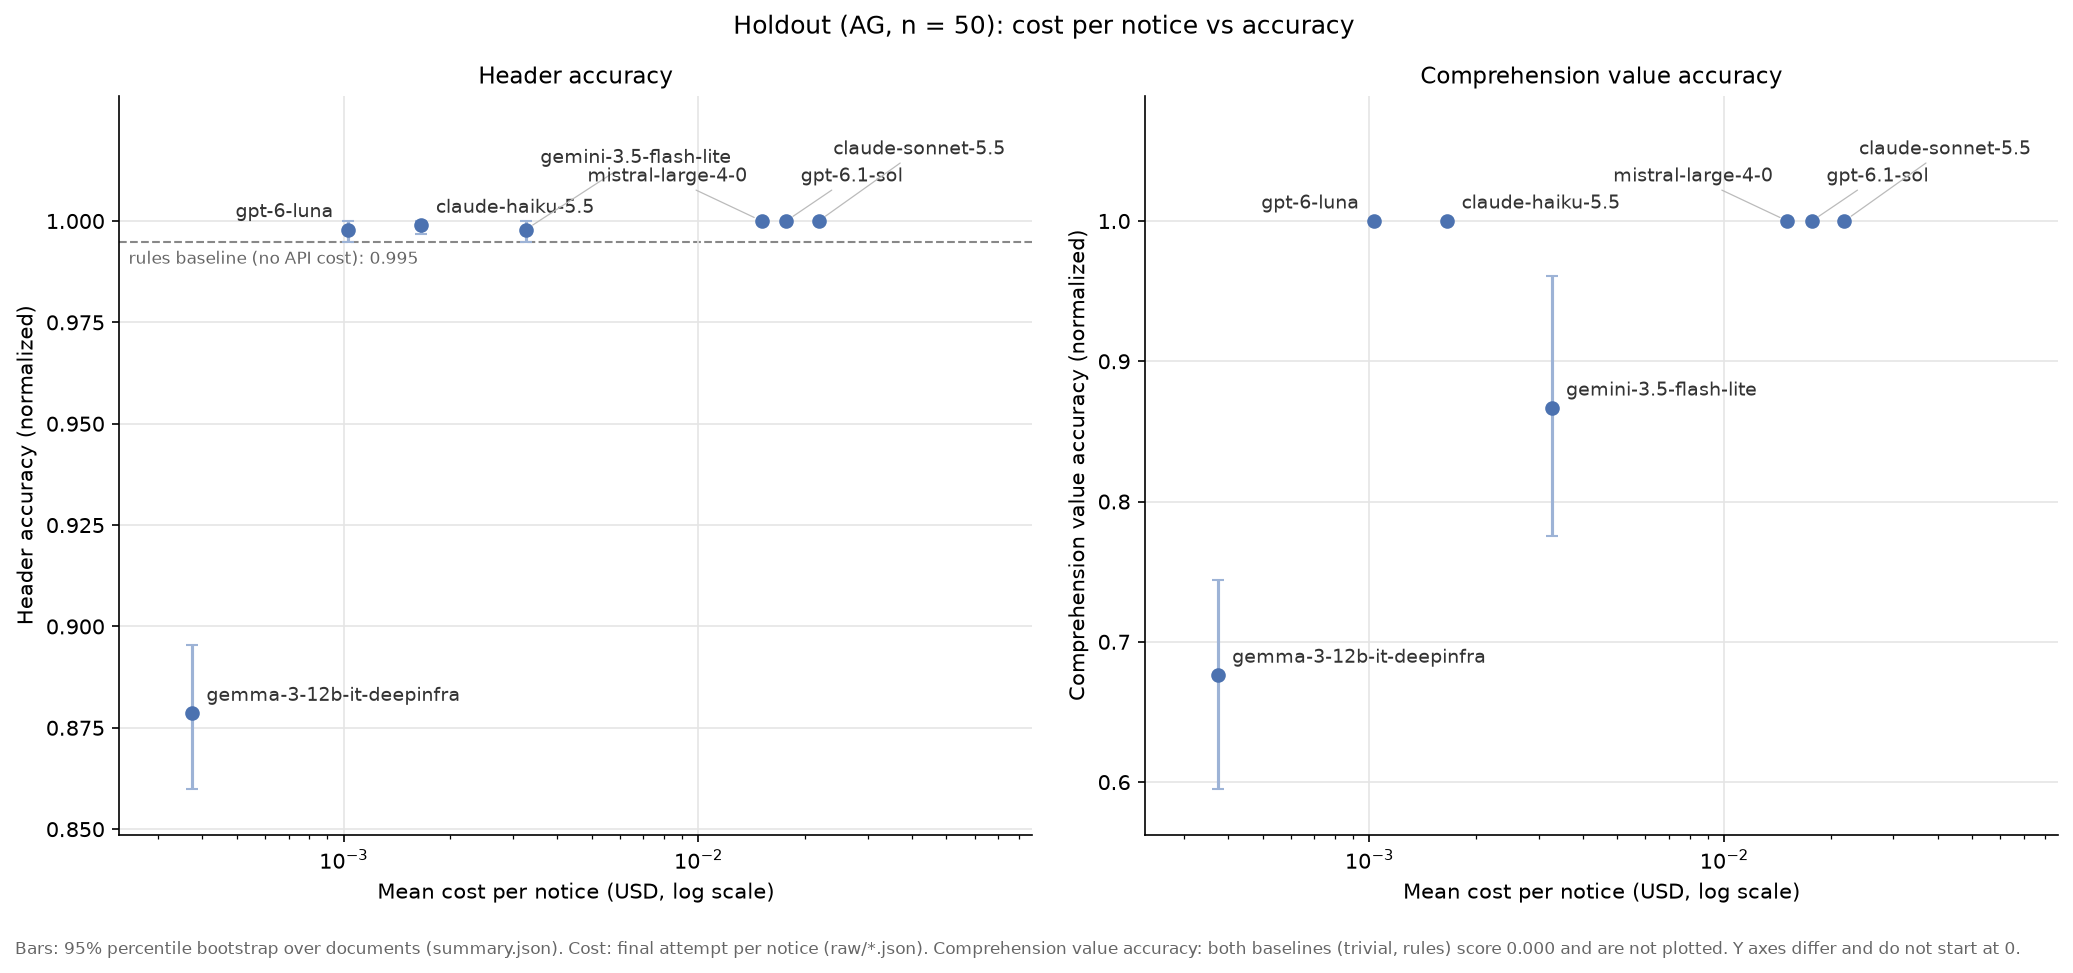

,mean cost / notice (USD),header acc: value,header acc: ci_low,header acc: ci_high,comp. value acc: value,comp. value acc: ci_low,comp. value acc: ci_high
model,,,,,,,
gpt-6-luna,0.001030,0.997888,0.994720,1.000000,1.000000,1.000000,1.000000
gpt-6.1-sol,0.017666,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
claude-haiku-5.5,0.001656,0.998944,0.996825,1.000000,1.000000,1.000000,1.000000
claude-sonnet-5.5,0.021818,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
gemini-3.5-flash-lite,0.003261,0.997888,0.994715,1.000000,0.866667,0.775701,0.960784
mistral-large-4-0,0.015078,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
gemma-3-12b-it-deepinfra,0.000373,0.878564,0.859852,0.895459,0.676190,0.594937,0.744000


In [21]:
PANELS = [
    ("group_accuracy_normalized:header", "Header accuracy (normalized)"),
    ("group_value_accuracy_normalized:comprehension", "Comprehension value accuracy (normalized)"),
]
h = HEADLINE["holdout"].set_index("competitor")
cost = COST["holdout"]["mean cost / notice (USD)"]

# Label placement only: several models sit at or near y = 1.0 at similar
# cost, so their labels are stacked in tiers above the points (tier 1 is
# closest), with a leader line from tier 2 up. (horizontal side, tier)
LABEL_POS = {
    "gpt-6-luna": ("left", 1),
    "claude-haiku-5.5": ("right", 1),
    "mistral-large-4-0": ("left", 2),
    "gpt-6.1-sol": ("right", 2),
    "claude-sonnet-5.5": ("right", 3),
}
# In the header panel gemini also sits at y ~ 1.0, next to haiku.
LABEL_POS_HEADER = {**LABEL_POS, "gemini-3.5-flash-lite": ("right", 3)}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), dpi=150, sharex=True)
tables = {}
for ax, (metric, ylabel) in zip(axes, PANELS):
    m = h[h["metric"] == metric]
    plot = cost.to_frame().join(m[["value", "ci_low", "ci_high"]])
    tables[metric] = plot
    ax.errorbar(plot["mean cost / notice (USD)"], plot["value"],
                yerr=[plot["value"] - plot["ci_low"], plot["ci_high"] - plot["value"]],
                fmt="o", color="#4C72B0", ecolor="#9DB3D6", elinewidth=1.5, capsize=3, markersize=6, zorder=3)
    positions = LABEL_POS_HEADER if metric == "group_accuracy_normalized:header" else LABEL_POS
    for model, r in plot.iterrows():
        side, tier = positions.get(model, ("right", 1))
        ax.annotate(model, (r["mean cost / notice (USD)"], r["value"]), textcoords="offset points",
                    xytext=(7 if side == "right" else -7, 6 + 13 * (tier - 1)),
                    ha="left" if side == "right" else "right", fontsize=9, color="#333333",
                    arrowprops=dict(arrowstyle="-", color="#BBBBBB", lw=0.6, shrinkA=0, shrinkB=4)
                    if tier > 1 else None)
    low = plot["ci_low"].min()
    if metric == "group_accuracy_normalized:header":
        rules = m.loc["baseline-rules", "value"]
        ax.axhline(rules, color="#888888", linestyle="--", linewidth=1, zorder=1)
        ax.annotate(f"rules baseline (no API cost): {rules:.3f}", (0.01, rules),
                    xycoords=("axes fraction", "data"), xytext=(0, -4), textcoords="offset points",
                    ha="left", va="top", fontsize=8, color="#666666")
        low = min(low, rules)
    span = 1 - low
    # Headroom above 1.0 for the stacked labels; no tick is drawn above 1.0.
    ax.set_ylim(low - 0.08 * span, 1 + 0.22 * span)
    ax.set_yticks([t for t in ax.get_yticks() if low - 0.08 * span <= t <= 1 + 1e-9])
    ax.set_xscale("log")
    ax.set_xlabel("Mean cost per notice (USD, log scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel.replace(" (normalized)", ""), fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(True, which="major", color="#E5E5E5", linewidth=0.8)
axes[0].set_xlim(cost.min() / 1.6, cost.max() * 4)

fig.suptitle("Holdout (AG, n = 50): cost per notice vs accuracy", fontsize=12)
fig.text(0.01, -0.03,
         "Bars: 95% percentile bootstrap over documents (summary.json). "
         "Cost: final attempt per notice (raw/*.json). "
         "Comprehension value accuracy: both baselines (trivial, rules) score 0.000 and are not plotted. "
         "Y axes differ and do not start at 0.",
         fontsize=8, color="#666666")
fig.tight_layout()
fig.savefig(FIG_DIR / "cost_vs_comprehension_holdout.png", bbox_inches="tight")
plt.show()
summary = cost.to_frame()
for m, t in tables.items():
    summary = summary.join(t[["value", "ci_low", "ci_high"]].add_prefix(f"{KEY_METRICS[m]}: "))
summary

## 8. Provider effects

### gemma-3-12b-it: NextBit vs DeepInfra (dev)

The same open-weight model was first run with OpenRouter's default routing,
which served it from NextBit (`dev-gemma-3-12b-it`), and then rerun pinned to
DeepInfra with `allow_fallbacks=false` (`dev-gemma-3-12b-it-deepinfra`).
NextBit runs are excluded from every other section.

In [22]:
gemma_runs = {"NextBit": NEXTBIT_RUN, "DeepInfra": "dev-gemma-3-12b-it-deepinfra"}
rows = []
for provider, run in gemma_runs.items():
    r = RAW[run]
    s = SUMMARIES[run]
    rows.append({"provider": provider, "run": run,
                 "provider_served": ", ".join(sorted(r["provider_served"].dropna().unique())),
                 "notices": len(r),
                 "empty completions (response_chars = 0)": int((r["response_chars"] == 0).sum()),
                 "completion_tokens = 1": int((r["completion_tokens"] == 1).sum()),
                 "finish_reason": dict(r["finish_reason"].value_counts()),
                 "parse status": s["format"]["status_counts"],
                 "max_tokens": s["run"]["params"]["max_tokens"]})
pd.DataFrame(rows).set_index("provider").T

provider,NextBit,DeepInfra
run,dev-gemma-3-12b-it,dev-gemma-3-12b-it-deepinfra
provider_served,NextBit,DeepInfra
notices,120,120
empty completions (response_chars = 0),62,0
completion_tokens = 1,62,0
finish_reason,{'stop': 120},{'stop': 120}
parse status,"{'ok': 58, 'failed': 0, 'no_response': 62}","{'ok': 120, 'failed': 0, 'no_response': 0}"
max_tokens,32768,8192


In [23]:
gemma_long = headline_long({p: r for p, r in gemma_runs.items()}, SUMMARIES)
t = gemma_long.assign(cell=gemma_long.apply(fmt_cell, axis=1)).pivot(index="competitor", columns="label", values="cell")
t[list(KEY_METRICS.values())]

label,comp. value acc,comp. null acc,F1 persons_added,F1 persons_removed,F1 persons_changed,act_subtypes micro-F1,extras key F1,header acc,global acc
competitor,,,,,,,,,
DeepInfra,"0.598 [0.527, 0.665]","0.977 [0.967, 0.986]","0.876 [0.813, 0.929]","0.984 [0.945, 1.000]","0.697 [0.538, 0.822]","0.440 [0.323, 0.552]","0.650 [0.535, 0.758]","0.902 [0.890, 0.914]","0.905 [0.895, 0.915]"
NextBit,"0.304 [0.222, 0.391]","0.467 [0.378, 0.557]","0.635 [0.484, 0.742]","0.667 [0.488, 0.809]","0.528 [0.316, 0.686]","0.292 [0.183, 0.403]","0.341 [0.224, 0.463]","0.444 [0.363, 0.528]","0.442 [0.361, 0.526]"


The NextBit scores above charge every empty completion as `no_output`. To
separate the empty completions from the quality of the answers that did
arrive, the next cell recomputes the key metrics for both providers on the
notices where NextBit returned text only. These notices are not a random
subset, so the comparison is descriptive; the prompt length of the two
groups is shown for that reason.

In [24]:
nb = RAW[NEXTBIT_RUN].set_index("doc_id")
answered = sorted(nb.index[nb["response_chars"] > 0])
print(f"notices with a NextBit answer: {len(answered)} of {len(nb)}")
print(nb.groupby(nb["response_chars"] > 0)["prompt_tokens"].describe()[["count", "mean", "50%", "min", "max"]]
      .rename(index={True: "answered", False: "empty"}))

rows = []
for provider, run in gemma_runs.items():
    df = FIELDS[run][FIELDS[run]["doc_id"].isin(answered)]
    for metric, label in KEY_METRICS.items():
        num, den = micro(df, metric)
        rows.append({"provider": provider, "label": label,
                     "cell": f"{num / den:.3f} ({num}/{den})" if den else "n/a"})
pd.DataFrame(rows).pivot(index="provider", columns="label", values="cell")[list(KEY_METRICS.values())]

notices with a NextBit answer: 58 of 120
                count         mean     50%     min     max
response_chars                                            
empty            62.0  5367.177419  5359.5  5243.0  5558.0
answered         58.0  5425.137931  5411.5  5260.0  5881.0


label,comp. value acc,comp. null acc,F1 persons_added,F1 persons_removed,F1 persons_changed,act_subtypes micro-F1,extras key F1,header acc,global acc
provider,,,,,,,,,
DeepInfra,0.621 (64/103),0.979 (462/472),0.839 (78/93),0.970 (32/33),0.698 (30/43),0.429 (36/84),0.602 (62/103),0.893 (982/1100),0.900 (1508/1675)
NextBit,0.602 (62/103),0.975 (460/472),0.833 (80/96),0.970 (32/33),0.667 (28/42),0.465 (40/86),0.549 (56/102),0.919 (1011/1100),0.915 (1533/1675)


### Mistral: unusable completions and the resume pass

The raw record of a document is overwritten when it is requested again, so
the state before a resume pass is not stored anywhere in the repository.
What can be read from the final records is (a) the in-call retries
(`attempts > 1`) and (b) which documents were requested in a later pass,
inferred from a gap of more than one hour in the request timestamps. Under
`raw_needs_request` in `src/run_eval.py`, a resume re-requests only
documents whose saved record is missing, has a status other than `ok`, or
is unusable (finish_reason `error` or no text); which of these applied to
each document before the resume is not recorded.

In [25]:
def passes(run, gap=pd.Timedelta(hours=1)):
    r = RAW[run].sort_values("timestamp").reset_index(drop=True)
    breaks = r["timestamp"].diff() > gap
    r["pass"] = breaks.cumsum() + 1
    return r


for split in SPLITS:
    run = MAIN_RUNS[split]["mistral-large-4-0"]
    r = passes(run)
    print(f"{run}: {r['pass'].nunique()} pass(es) by timestamp; documents per pass:",
          {int(k): int(v) for k, v in r["pass"].value_counts().sort_index().items()})
    for p, g in r.groupby("pass"):
        print(f"  pass {p}: {g['timestamp'].min():%Y-%m-%d %H:%M} – {g['timestamp'].max():%Y-%m-%d %H:%M} UTC,"
              f" {len(g)} documents: " + (", ".join(g["doc_id"]) if p > 1
                                            else f"first {g['doc_id'].iloc[0]}, last {g['doc_id'].iloc[-1]}"))

mistral_dev = passes(MAIN_RUNS["dev"]["mistral-large-4-0"])
mistral_dev[(mistral_dev["pass"] > 1) | (mistral_dev["attempts"] > 1) | (mistral_dev["status"] != "ok")][
    ["doc_id", "pass", "timestamp", "attempts", "status", "finish_reason", "response_chars", "error"]
]

holdout-mistral-large-4-0: 2 pass(es) by timestamp; documents per pass: {1: 27, 2: 23}
  pass 1: 2026-10-13 12:45 – 2026-10-13 13:30 UTC, 27 documents: first 0121, last 0147
  pass 2: 2026-10-13 15:36 – 2026-10-13 16:19 UTC, 23 documents: 0148, 0149, 0150, 0151, 0152, 0153, 0154, 0155, 0156, 0157, 0158, 0159, 0160, 0161, 0162, 0163, 0164, 0165, 0166, 0167, 0168, 0169, 0170
dev-mistral-large-4-0: 2 pass(es) by timestamp; documents per pass: {1: 108, 2: 12}
  pass 1: 2026-10-11 23:30 – 2026-10-12 00:50 UTC, 108 documents: first 0001, last 0120
  pass 2: 2026-10-12 07:42 – 2026-10-12 07:56 UTC, 12 documents: 0002, 0013, 0018, 0027, 0028, 0033, 0036, 0037, 0046, 0057, 0084, 0113


,doc_id,pass,timestamp,attempts,status,finish_reason,response_chars,error
108,0002,2,2026-10-12 07:42:21.078777+00:00,1,ok,stop,1097,None
109,0013,2,2026-10-12 07:43:25.060995+00:00,1,ok,stop,2041,None
110,0018,2,2026-10-12 07:44:42.289444+00:00,3,ok,stop,1922,None
111,0027,2,2026-10-12 07:46:20.598673+00:00,1,ok,stop,1976,None
112,0028,2,2026-10-12 07:46:53.003484+00:00,1,ok,stop,1595,None
113,0033,2,2026-10-12 07:48:04.168307+00:00,1,ok,stop,1296,None
114,0036,2,2026-10-12 07:48:42.991205+00:00,2,ok,stop,1198,None
115,0037,2,2026-10-12 07:49:13.089170+00:00,1,ok,stop,1158,None
116,0046,2,2026-10-12 07:54:34.872840+00:00,4,ok,stop,1643,None
117,0057,2,2026-10-12 07:55:22.774408+00:00,1,ok,stop,1622,None


In [26]:
mistral_holdout = passes(MAIN_RUNS["holdout"]["mistral-large-4-0"])
mistral_holdout[mistral_holdout["attempts"] > 1][["doc_id", "pass", "timestamp", "attempts", "status", "finish_reason"]]

,doc_id,pass,timestamp,attempts,status,finish_reason
1,0122,1,2026-10-13 12:48:11.164647+00:00,2,ok,stop
2,0123,1,2026-10-13 12:51:33.923631+00:00,3,ok,stop
3,0124,1,2026-10-13 12:53:31.482536+00:00,2,ok,stop
7,0128,1,2026-10-13 12:57:35.750341+00:00,2,ok,stop
8,0129,1,2026-10-13 12:58:47.795794+00:00,2,ok,stop
11,0132,1,2026-10-13 13:06:30.853708+00:00,2,ok,stop
12,0133,1,2026-10-13 13:07:51.956315+00:00,2,ok,stop
28,0149,2,2026-10-13 15:39:17.763708+00:00,2,ok,stop
41,0162,2,2026-10-13 16:02:46.928935+00:00,2,ok,stop


In [27]:
# How the one remaining failure (dev, status error) is scored.
s = SUMMARIES[MAIN_RUNS["dev"]["mistral-large-4-0"]]
print("parse status counts:", s["format"]["status_counts"])
df = FIELDS[MAIN_RUNS["dev"]["mistral-large-4-0"]]
failed_docs = sorted(df.loc[df["outcome_normalized"] == "no_output", "doc_id"].unique())
print("documents scored no_output:", failed_docs)
df[df["doc_id"].isin(failed_docs)]["outcome_normalized"].value_counts()

parse status counts: {'ok': 119, 'failed': 0, 'no_response': 1}
documents scored no_output: ['0084']


outcome_normalized
no_output             37
excluded_uncertain     1
Name: count, dtype: int64

## 9. Gold audit: dev results before and after the correction

The gold corrections of 2026-10-14 (`corrections/gold_corrections_2026-10-14.json`,
applied in commit 9de7ab8) changed 19 dev values in 15 notices and 3 holdout
`extras.loeschung_reason` values. The results before the correction are read
from the tag `pre-gold-correction` with `git show`. The evaluator code
(`src/evaluate.py`, `src/parse_responses.py`) is unchanged between the
commits that produced the two sets of results, and the cell below checks
that every changed outcome lies in a corrected notice.

In [28]:
CORRECTIONS = json.loads((ROOT / "corrections" / "gold_corrections_2026-10-14.json").read_text(encoding="utf-8"))
corr = pd.DataFrame(CORRECTIONS)
print(corr.groupby("split").agg(values=("path", "size"), notices=("doc_id", "nunique")))
corr[corr["split"] == "dev"][["doc_id", "path", "expected_old", "new"]]

         values  notices
split                   
dev          19       15
holdout       3        3


,doc_id,path,expected_old,new
0,0004,extras.nominal_value_chf,None,100.0
1,0005,extras.revision,None,opting-out
2,0006,extras.prior_publication_page,None,0
3,0008,domicile_new,Rubigenstrasse 66,"Rubigenstrasse 66, 3123 Belp"
4,0008,domicile_previous,"Waisenhausstrasse 8, 3600 Thun","Rubigenstrasse 66, 3123 Belp"
5,0009,extras.mitteilungen,Mitteilungen an die Gesellschafter: per Brief oder E-Mail.,per Brief oder E-Mail
6,0017,act_subtypes,[sitzverlegung],[]
7,0024,extras.prior_publication_page,None,5
8,0025,extras.nominal_value_chf,None,100.0
9,0027,"persons_changed[name=Eftodii, Valeriu].nationality_new",None,rumänisch


In [29]:
TAG = "pre-gold-correction"
KEYS = ["doc_id", "field", "item", "attribute"]
corrected_docs = {split: set(corr.loc[corr["split"] == split, "doc_id"]) for split in SPLITS}


def outcome_changes(run, split):
    old = load_fields(run, TAG)
    new = FIELDS[run]
    m = old.merge(new, on=KEYS, how="outer", suffixes=("_old", "_new"), indicator=True)
    changed = m[(m["_merge"] != "both") | (m["outcome_normalized_old"] != m["outcome_normalized_new"])
                | (m["gold_old"] != m["gold_new"])]
    outside = set(changed["doc_id"]) - corrected_docs[split]
    assert not outside, f"{run}: changes outside corrected notices: {sorted(outside)}"
    return changed


before_after = []
for competitor, run in MAIN_RUNS["dev"].items():
    old = headline_long({competitor: run}, ref=TAG)
    new = HEADLINE["dev"][HEADLINE["dev"]["competitor"] == competitor]
    for (_, o), (_, n) in zip(old.iterrows(), new.iterrows()):
        assert o["metric"] == n["metric"]
        before_after.append({"competitor": competitor, "label": n["label"],
                             "before": f"{o['value']:.3f} ({o['numerator']}/{o['denominator']})" if pd.notna(o["value"]) else "n/a",
                             "after": f"{n['value']:.3f} ({n['numerator']}/{n['denominator']})" if pd.notna(n["value"]) else "n/a",
                             "delta": n["value"] - o["value"]})
before_after = pd.DataFrame(before_after)
delta = before_after.pivot(index="competitor", columns="label", values="delta").loc[COMPETITORS, list(KEY_METRICS.values())]
delta.style.format("{:+.4f}").background_gradient(cmap="RdBu", vmin=-0.02, vmax=0.02)

label,comp. value acc,comp. null acc,F1 persons_added,F1 persons_removed,F1 persons_changed,act_subtypes micro-F1,extras key F1,header acc,global acc
competitor,,,,,,,,,
baseline-trivial,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,-0.0014
baseline-rules,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,-0.0014
gpt-6-luna,-0.0044,+0.0020,+0.0000,+0.0000,+0.0000,+0.0043,+0.0126,+0.0000,+0.0003
gpt-6.1-sol,+0.0152,+0.0061,+0.0000,+0.0000,+0.0000,+0.0043,+0.0193,+0.0000,+0.0026
claude-haiku-5.5,+0.0153,+0.0061,+0.0000,+0.0000,+0.0000,+0.0043,+0.0121,+0.0000,+0.0026
claude-sonnet-5.5,+0.0156,+0.0061,+0.0000,+0.0000,+0.0000,+0.0043,+0.0120,+0.0000,+0.0026
gemini-3.5-flash-lite,-0.0234,+0.0000,+0.0000,+0.0000,+0.0000,+0.0041,+0.0119,+0.0000,-0.0014
mistral-large-4-0,+0.0156,+0.0060,+0.0000,+0.0000,+0.0000,+0.0042,+0.0207,+0.0000,+0.0026
gemma-3-12b-it-deepinfra,-0.0100,+0.0039,+0.0000,+0.0000,+0.0000,+0.0029,-0.0062,+0.0000,+0.0000


In [30]:
# Before / after values for the comprehension group, where the domicile
# fields sit.
before_after[before_after["label"].isin(["comp. value acc", "comp. null acc", "global acc"])].pivot(
    index="competitor", columns="label", values=["before", "after"]
).loc[COMPETITORS]

before                                                after                                    
label                      comp. null acc  comp. value acc         global acc   comp. null acc  comp. value acc         global acc
competitor                                                                                                                        
baseline-trivial          1.000 (991/991)    0.000 (0/199)  0.498 (1727/3467)  1.000 (986/986)    0.000 (0/204)  0.497 (1722/3467)
baseline-rules            1.000 (991/991)    0.000 (0/199)  0.942 (3267/3467)  1.000 (986/986)    0.000 (0/204)  0.941 (3262/3467)
gpt-6-luna                0.998 (989/991)  0.980 (195/199)  0.997 (3457/3467)  1.000 (986/986)  0.975 (199/204)  0.997 (3458/3467)
gpt-6.1-sol               0.994 (985/991)  0.980 (195/199)  0.997 (3457/3467)  1.000 (986/986)  0.995 (203/204)  1.000 (3466/3467)
claude-haiku-5.5          0.994 (985/991)  0.975 (194/199)  0.997 (3456/3467)  1.000 (986/986)  0.990 (202/204)  0.999 (3465/3467)
claude-sonnet-5.5         0.994 (985/991)  0.965 (192/199)  0.996 (3454/3467)  1.000 (986/986)  0.980 (200/204)  0.999 (3463/3467)
gemini-3.5-flash-lite     1.000 (991/991)  0.955 (190/199)  0.995 (3448/3467)  1.000 (986/986)  0.931 (190/204)  0.993 (3443/3467)
mistral-large-4-0         0.986 (977/991)  0.965 (192/199)  0.988 (3427/3467)  0.992 (978/986)  0.980 (200/204)  0.991 (3436/3467)
gemma-3-12b-it-deepinfra  0.973 (964/991)  0.608 (121/199)  0.905 (3138/3467)  0.977 (963/986)  0.598 (122/204)  0.905 (3138/3467)

### Where the changes come from

For each dev run, every row of `fields.csv` whose outcome (or gold value)
differs between the tag and the current results is classified as
*fixed* (a failure that is now correct), *broken* (a correct outcome that
is now a failure) or *other* (a failure that changed type, or a row that
appears only on one side, as person rows keyed by name can). The domicile
corrections apply the frozen prompt's rule for the `Bisher` block, quoted
from the corrections file below.

In [31]:
print(corr.loc[(corr["split"] == "dev") & corr["path"].str.startswith("domicile_"), "reason"].iloc[0])

Frozen prompt, Seat and address: domicile_new/domicile_previous are filled when the notice shows a Bisher block with an address; 'Fill both as printed, even when street and town are the same on both sides'; format '<street>, <postcode> <town>'.


In [32]:
GOOD = OK_OUTCOMES | {"matched"}


def change_kind(r):
    if r["_merge"] != "both":
        return "other"
    old_ok, new_ok = r["outcome_normalized_old"] in GOOD, r["outcome_normalized_new"] in GOOD
    if not old_ok and new_ok:
        return "fixed"
    if old_ok and not new_ok:
        return "broken"
    return "other"


changes = []
for competitor, run in MAIN_RUNS["dev"].items():
    c = outcome_changes(run, "dev")
    if len(c):
        changes.append(c.assign(competitor=competitor, kind=c.apply(change_kind, axis=1)))
changes = pd.concat(changes, ignore_index=True)
changes["target"] = changes["field"] + np.where(changes["attribute"] != "", "." + changes["attribute"], "")
pd.crosstab([changes["competitor"]], [changes["kind"]]).reindex(COMPETITORS, fill_value=0)

kind,broken,fixed,other
competitor,,,
baseline-trivial,6,1,12
baseline-rules,6,1,12
gpt-6-luna,4,13,2
gpt-6.1-sol,0,19,0
claude-haiku-5.5,0,17,2
claude-sonnet-5.5,0,16,3
gemini-3.5-flash-lite,7,8,4
mistral-large-4-0,0,18,1
gemma-3-12b-it-deepinfra,4,5,10


In [33]:
pd.crosstab(changes["target"], [changes["kind"]], margins=True)

kind,broken,fixed,other,All
target,,,,
act_subtypes,0,9,0,9
domicile_new,12,19,5,36
domicile_previous,13,19,4,36
extras,1,38,33,72
persons_changed,0,0,4,4
persons_changed.nationality_new,1,13,0,14
All,27,98,46,171


In [34]:
# The domicile rows: counts per model, then every row.
dom = changes[changes["field"].isin(["domicile_new", "domicile_previous"])]
display(pd.crosstab(dom["competitor"], [dom["doc_id"], dom["kind"]]).reindex(COMPETITORS, fill_value=0))
dom[["competitor", "doc_id", "field", "gold_old", "gold_new", "prediction_new",
     "outcome_normalized_old", "outcome_normalized_new", "kind"]].sort_values(["competitor", "doc_id", "field"])

doc_id                     0008               0063               0072         0119      
kind                     broken fixed other broken fixed other broken fixed broken fixed
competitor                                                                              
baseline-trivial              0     0     2      2     0     0      2     0      2     0
baseline-rules                0     0     2      2     0     0      2     0      2     0
gpt-6-luna                    0     2     0      2     0     0      0     2      2     0
gpt-6.1-sol                   0     2     0      0     2     0      0     2      0     2
claude-haiku-5.5              0     2     0      0     2     0      0     2      0     2
claude-sonnet-5.5             0     2     0      0     2     0      0     2      0     2
gemini-3.5-flash-lite         0     0     2      2     0     0      2     0      2     0
mistral-large-4-0             0     2     0      0     2     0      0     2      0     2
gemma-3-12b-it-deepinfra      1     0     1      0     0     2      2     0      0     2

,competitor,doc_id,field,gold_old,gold_new,prediction_new,outcome_normalized_old,outcome_normalized_new,kind
22,baseline-rules,0008,domicile_new,"""Rubigenstrasse 66""","""Rubigenstrasse 66, 3123 Belp""",null,omission,omission,other
23,baseline-rules,0008,domicile_previous,"""Waisenhausstrasse 8, 3600 Thun""","""Rubigenstrasse 66, 3123 Belp""",null,omission,omission,other
30,baseline-rules,0063,domicile_new,null,"""Gerechtigkeitsgasse 81, 3011 Bern""",null,correct_null,omission,broken
31,baseline-rules,0063,domicile_previous,null,"""Gerechtigkeitsgasse 81, 3011 Bern""",null,correct_null,omission,broken
33,baseline-rules,0072,domicile_new,null,"""Brown-Boveri-Strasse 5, 8050 Zürich""",null,correct_null,omission,broken
34,baseline-rules,0072,domicile_previous,null,"""Brown-Boveri-Strasse 5, 8050 Zürich""",null,correct_null,omission,broken
35,baseline-rules,0119,domicile_new,null,"""Rosengartenstrasse 3, 8037 Zürich""",null,correct_null,omission,broken
36,baseline-rules,0119,domicile_previous,null,"""Rosengartenstrasse 3, 8037 Zürich""",null,correct_null,omission,broken
3,baseline-trivial,0008,domicile_new,"""Rubigenstrasse 66""","""Rubigenstrasse 66, 3123 Belp""",null,omission,omission,other
4,baseline-trivial,0008,domicile_previous,"""Waisenhausstrasse 8, 3600 Thun""","""Rubigenstrasse 66, 3123 Belp""",null,omission,omission,other


Holdout: the three holdout corrections touch `extras.loeschung_reason`
only, a value scored by `extras_value_accuracy_normalized` and not by any of
the key metrics above. The cell below lists every holdout headline metric
(all of them, not only the key ones) whose numerator or denominator changed.

In [35]:
rows = []
for competitor, run in MAIN_RUNS["holdout"].items():
    old = load_summary(run, TAG)["headline"]
    for metric, n in SUMMARIES[run]["headline"].items():
        o = old[metric]
        if (o["numerator"], o["denominator"]) != (n["numerator"], n["denominator"]):
            rows.append({"competitor": competitor, "metric": metric,
                         "before": f"{o['numerator']}/{o['denominator']}", "after": f"{n['numerator']}/{n['denominator']}"})
for competitor, run in MAIN_RUNS["holdout"].items():
    outcome_changes(run, "holdout")  # asserts that changes stay inside corrected notices
pd.DataFrame(rows, columns=["competitor", "metric", "before", "after"])

,competitor,metric,before,after
0,gemini-3.5-flash-lite,extras_value_accuracy_normalized,33/39,34/39


### How the gold errors were found (dev)

Three methods produced the cells checked by hand; each verdict was written
by the annotator in the CSVs under `results/gold_audit/dev/`.

- **Model-consensus candidates** (`src/audit_gold.py`): cells where at
  least 3 of five models (gpt-6-luna, gpt-6.1-sol, claude-haiku-5.5,
  claude-sonnet-5.5, gemini-3.5-flash-lite) give the same value and that
  value differs from the gold. A cell is a field, an `extras` key, or one
  attribute of a person that both the gold and the model list; a model
  without parsed output abstains.
- **Rule sweep** (`src/gold_rule_sweep.py`): nine rules of the frozen prompt
  turned into literal string checks on the gold and its notice (for
  example, a "Bisher" block with an address but a null `domicile_previous`).
  It uses no model output. A flagged row is a case to inspect, not an error.
- **Random sample** (`src/audit_gold.py`): 100 cells drawn with fixed seeds
  from the cells where all five models agree with the gold, to estimate the
  gold's error rate where the models give no reason for doubt. Cells where
  the models disagree among themselves without a consensus of 3 against the
  gold are in neither the candidates nor the sample.

In [36]:
# Gold audit of the dev split: the three CSVs with the annotator's verdicts.
AUDIT_DIR = RESULTS / "gold_audit" / "dev"
AUDIT = {name: pd.read_csv(AUDIT_DIR / f"{name}.csv", dtype=str, keep_default_na=False, encoding="utf-8")
         for name in ("candidates", "rule_sweep", "random_sample")}
for name, df in AUDIT.items():
    assert (df["verdict"] != "").all(), f"{name}: rows without a verdict"

print("Model-consensus candidates, by verdict:")
print(AUDIT["candidates"]["verdict"].value_counts().to_string(), "\n")
print("Rule-sweep rows, by verdict:")
print(AUDIT["rule_sweep"]["verdict"].value_counts().to_string(), "\n")

sample = AUDIT["random_sample"]
k, n = int((sample["verdict"] == "gold_error").sum()), len(sample)
# alpha = 0.10 two-sided gives the one-sided 95% upper bound.
_, upper = proportion_confint(k, n, alpha=0.10, method="beta")
print(f"Random sample: {n} cells, {k} gold errors; "
      f"one-sided 95% Clopper-Pearson upper bound on the error rate: {upper:.3f}\n")


# Which method flagged each applied dev correction, matched by doc_id and
# the path used in the corrections file.
def _candidate_path(r):
    if r["field"] == "extras":
        return f"extras.{r['item']}"
    if r["attribute"]:
        return f"{r['field']}[name={r['item']}].{r['attribute']}"
    return r["field"]


flagged = {
    "model consensus": {(r["doc_id"], _candidate_path(r))
                        for _, r in AUDIT["candidates"].iterrows() if r["verdict"] == "gold_error"},
    "rule sweep": {(r["doc_id"], re.sub(r"\[(?!name=)", "[name=", r["field"]))
                   for _, r in AUDIT["rule_sweep"].iterrows() if r["verdict"] == "gold_error"},
}
dev_corr = corr[corr["split"] == "dev"]
found = pd.DataFrame({method: [(d, p) in cells for d, p in zip(dev_corr["doc_id"], dev_corr["path"])]
                      for method, cells in flagged.items()})
assert (found.any(axis=1)).all(), "a correction flagged by neither method"
print(f"The {len(dev_corr)} dev corrections, by the method that flagged them:")
pd.crosstab(found["model consensus"], found["rule sweep"], margins=True)

Model-consensus candidates, by verdict:
verdict
gold_error    17
ambiguous      6 

Rule-sweep rows, by verdict:
verdict
gold_error    17 

Random sample: 100 cells, 0 gold errors; one-sided 95% Clopper-Pearson upper bound on the error rate: 0.030

The 19 dev corrections, by the method that flagged them:


rule sweep,False,True,All
model consensus,,,
False,0,2,2
True,2,15,17
All,2,17,19


## 10. Conclusions

On the holdout (50 notices from canton AG), five of the seven models extract
the comprehension fields without a single error, at mean costs per notice
from $0.00103 to $0.02182. The header fields are already handled by rules;
the largest differences between models are in the fields that need
comprehension.

Differences between two models come from a paired bootstrap over notices
(95% CI, section 4).

1. **Header fields do not need an LLM.** On the holdout, the rules baseline
   reaches a header accuracy of 0.995 (trivial baseline: 0.227). It scores
   0.000 on comprehension value accuracy, the three person lists and
   `extras` key F1, which is where the models add value (section 2).

2. **The holdout is saturated at the top.** On the holdout, gpt-6-luna,
   gpt-6.1-sol, claude-haiku-5.5, claude-sonnet-5.5 and mistral-large-4-0
   all reach a comprehension value accuracy of 1.000 (105/105). Holdout
   notices with no error in any field or person list (post-hoc, section 5):
   sol, sonnet and mistral 50/50, haiku 47/50, luna 46/50. With so few
   errors, the holdout cannot rank these five models. Zero errors is not
   proof of perfection: the exact (Clopper–Pearson) interval for 105/105 is
   [0.965, 1.000] (section 3).

3. **Cheap models come close to the expensive ones.** Mean cost per holdout
   notice: luna $0.00103, haiku $0.00166, sol $0.01767, sonnet $0.02182,
   mistral $0.01508 (section 7). Sol costs about 11 times as much as haiku
   and 17 times as much as luna. On dev, sol − luna in comprehension value
   accuracy is +0.0196 [−0.0053, 0.0538]: no difference was detected. Their
   dev global accuracy differs, but only by +0.0023 [0.0003, 0.0049].
   Caveat: luna's holdout `extras` key F1 is 0.901 [0.769, 0.968] against
   1.000 for sol; this pair was not tested.

4. **gemini-3.5-flash-lite is measurably weaker on comprehension.** Holdout
   comprehension value accuracy: 0.867 against 1.000 for haiku, a difference
   of +0.1333 [0.0400, 0.2250]. The gap repeats on dev: +0.0588 [0.0155,
   0.1073]. Gemini has the lowest median latency, 2.1 s per holdout notice
   against 6.2 s for haiku (section 7). But haiku is both cheaper ($0.00166
   against $0.00326 per holdout notice) and higher on comprehension value
   accuracy.

5. **A small open-weight model is not usable here, and the provider
   matters.** gemma-3-12b-it on DeepInfra is the cheapest model ($0.00037
   per holdout notice), but its holdout header accuracy of 0.879 is below
   the rules baseline. It gets 1/50 holdout notices fully correct on
   fields, 0/50 with persons (section 5). Through OpenRouter's default
   routing (NextBit), it returned empty completions on 62 of 120 dev
   notices; dev global accuracy fell to 0.442, against 0.905 on DeepInfra.
   On the 58 dev notices NextBit answered, quality was similar (global
   accuracy 0.915 against 0.900; not a random subset; section 8). Lesson:
   pin and report the provider when benchmarking open-weight models.

6. **The labels had to be audited too.** The gold correction changed 19
   values in 15 dev notices and 3 in the holdout (section 9). In dev
   comprehension value accuracy, it raised sol, haiku, sonnet and mistral by
   +0.0152 to +0.0156, and lowered luna (−0.0044), gemini (−0.0234) and
   gemma (−0.0100). Eight dev corrections are domiciles: six "Bisher" values
   that the old gold left empty (notices 0063, 0072 and 0119) and two wrong
   values in notice 0008. Luna had left them empty in two of these notices,
   gemini in all three. These corrections apply a rule quoted from the
   frozen prompt. No holdout key metric changed. The errors were found by
   model consensus (at least 3 of the five audit models listed in section 9
   agreeing against the gold) and by a sweep of frozen-prompt rules; a
   random sample of 100 cells where all five audit models agree with the
   gold found 0 errors (one-sided 95% upper bound 0.030). Consensus
   candidates can favour the consensus models, but the rule sweep, which
   uses no model output, flagged 17 of the 19 dev corrections (15 together
   with model consensus, 2 on its own; the other 2 came from consensus
   only). Caveat: the correction moved models in opposite directions (dev:
   sol 19 rows fixed, 0 broken; gemini 8 fixed, 7 broken), so the gold is
   itself a source of ranking uncertainty.

### Recommendation

On this evidence, claude-haiku-5.5 is the strongest choice for its cost:
1.000 comprehension value accuracy on the holdout, 47/50 holdout notices
fully correct and 0.990 comprehension value accuracy on dev, at $0.00166 per
holdout notice. gpt-6-luna is the cheapest strong option ($0.00103), but it
has the lowest holdout `extras` key F1 among the five strong models (0.901)
and 46/50 fully correct notices. Rules can serve as a cheap cross-check on
the header fields the LLM returns (rules baseline: 0.995 holdout header
accuracy), not as a replacement. This rests on 50 holdout notices from one
canton and is not a guarantee for other cantons.

### Limitations

- The holdout has 50 notices from one canton (AG); the top of the ranking is saturated.
- Cost and latency cover the final attempt per notice; earlier attempts (in-call retries, calls superseded by a resume pass) are not counted, so totals are lower bounds (section 7).
- Clopper–Pearson intervals treat each field as an independent trial; fields within a notice are correlated, so these intervals are too narrow. The bootstrap intervals resample whole notices and do not have this problem (section 3).
- The 12 paired comparisons (section 4) are not corrected for multiple comparisons.
- Open-weight results depend on the serving provider (section 8).
- Cells where the audit models disagree among themselves, without a 3-model consensus against the gold, were neither candidates nor in the random sample, so they were audited only by the rule sweep.
- The gold was annotated by a single annotator; inter-annotator agreement was not measured.
- Each model was run once per split; run-to-run variation was not measured.